In [1]:
# import classy module
from classy import Class
# uncomment to get plots displayed in notebook
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# create an instance of CLASS
model1 = Class()
model2 = Class()
model3 = Class()
model4 = Class()

In [3]:
# Set the model from CLASS
beta1 = {
        'omega_b':0.02238280,
        'omega_cdm':0.1201075,
        'H0':70.0,
        'A_s':2.100549e-09,
        'n_s':0.9660499,
        # other fixed parameters
        'N_ur':0.044,
        'N_ncdm':1,
        'm_ncdm':0.06,
        'T_ncdm':0.71611,
        'deg_ncdm': 3,
        'beta_ncdm':0.0,
        # settings for the output quantites
        'output':'mPk, tCl, pCl, lCl,dTk',
        'lensing':'yes',
        'P_k_max_h/Mpc':1.0,
        'non_linear':'none',
        'Omega_fld': 0.0,
        'Omega_scf': -1,
        'Omega_Lambda': 0.0,
        'scf_parameters': '1.0, -6.0, 6.0, 0.0',
        'attractor_ic_scf': 'no',
        'scf_tuning_index': 1,
        
}
model1.set(beta1)
model1.compute()





# Extract needed quantities for model 1

bg1 = model1.get_background()
# to check the quantities you can get from background
print(bg1.keys())

#redshift and scale factor
z1 = bg1['z']
a1 = 1.0 / (1.0 + z1)

#scalar field quantities
phi_scf1 = bg1['phi_scf']
dphi_scf1 = bg1['phi\'_scf']
rho_scf1 = bg1['(.)rho_scf']
p_scf1 = bg1['(.)p_scf']
V_scf1 = bg1['V_scf']
ddV_scf1 = bg1['V\'\'_scf']
w_phi1 =  p_scf1 / rho_scf1
# phi0 is the CURRENT value (at z=0, which is the LAST element)
phi0_1 = phi_scf1[-1]
#Neutrinos quantities
rho_nu1 = bg1['(.)rho_ncdm[0]']
p_nu1 = bg1['(.)p_ncdm[0]']
w_nu1 = p_nu1 / rho_nu1

drho_da1 = np.gradient(rho_nu1, a1)
dp_da1   = np.gradient(p_nu1, a1)

ca2_nu1 = dp_da1 / drho_da1

# The hubble parameter evolution
H1 = bg1['H [1/Mpc]']

# Calculate critical density
rho_crit1 = 3 * H1**2 / (8 * np.pi)  # in CLASS units

# You may also want to extract other density components to plot
rho_cdm1 = bg1['(.)rho_cdm']  # Cold dark matter
rho_b1 = bg1['(.)rho_b']      # Baryons
rho_g1 = bg1['(.)rho_g']      # Photons
rho_ur1 = bg1['(.)rho_ur']    # Ultra-relativistic species



# Get beta from your parameters
beta1_val = 0.0


# Compute w_eff (equation 19)

H_conf1 = a1* H1 # conformal Hubble: H = a * H_cosmic

w_eff1 = w_phi1 + (beta1_val * dphi_scf1 * (rho_nu1 - 3*p_nu1)) / (3 * H_conf1* rho_scf1)


#Call delta_nu and gravitational potential 

sources1, k_array1, tau_array1 = model1.get_sources()

k_target1 = 1e-3 # Choose your k scale in Mpc^-1
k_index = np.argmin(np.abs(k_array1 - k_target1))
phi_plus_psi1 = sources1['phi_plus_psi'][k_index]
delta_nu1 = sources1['delta_ncdm[0]'][k_index]

# Convert tau to redshift to check evolution of phi+psi
z_array1 = model1.z_of_tau(tau_array1)






dict_keys(['z', 'proper time [Gyr]', 'conf. time [Mpc]', 'H [1/Mpc]', 'comov. dist.', 'ang.diam.dist.', 'lum. dist.', 'comov.snd.hrz.', '(.)rho_g', '(.)rho_b', '(.)rho_cdm', '(.)rho_ncdm[0]', '(.)p_ncdm[0]', '(.)rho_ur', '(.)rho_crit', '(.)rho_scf', '(.)p_scf', '(.)p_prime_scf', 'phi_scf', "phi'_scf", 'V_scf', "V'_scf", "V''_scf", '(.)rho_tot', '(.)p_tot', '(.)p_tot_prime', 'Omega_r(z)', 'Omega_m(z)', 'gr.fac. D', 'gr.fac. f'])


In [4]:
beta2 = {
        'omega_b':0.02238280,
        'omega_cdm':0.1201075,
        'H0':70.0,
        'A_s':2.100549e-09,
        'n_s':0.9660499,
        # other fixed parameters
        'N_ur':0.044,
        'N_ncdm':1,
        'm_ncdm':0.06,
        'T_ncdm':0.71611,
        'deg_ncdm': 3,
        'beta_ncdm':0.8,
        # settings for the output quantites
        'output':'mPk, tCl, pCl, lCl,dTk',
        'lensing':'yes',
        'P_k_max_h/Mpc':1.0,
        'non_linear':'none',
        'Omega_fld': 0.0,
        'Omega_scf': -1,
        'Omega_Lambda': 0.0,
        'scf_parameters': '1.0, -6.0, 6.0, 0.0',
        'attractor_ic_scf': 'no',
        'scf_tuning_index': 1,
        
}
model2.set(beta2)
model2.compute()


# Extract needed quantities for model 2

bg2 = model2.get_background()
# to check the quantities you can get from background
print(bg2.keys())

#redshift and scale factor
z2 = bg2['z']
a2 = 1.0 / (1.0 + z2)

#scalar field quantities
phi_scf2 = bg2['phi_scf']
dphi_scf2 = bg2['phi\'_scf']
rho_scf2 = bg2['(.)rho_scf']
p_scf2 = bg2['(.)p_scf']
V_scf2 = bg2['V_scf']
ddV_scf2 = bg2['V\'\'_scf']
w_phi2 =  p_scf2 / rho_scf2
# phi0 is the CURRENT value (at z=0, which is the LAST element)
phi0_2 = phi_scf2[-1]
#Neutrinos quantities
rho_nu2 = bg2['(.)rho_ncdm[0]']
p_nu2 = bg2['(.)p_ncdm[0]']
w_nu2 = p_nu2 / rho_nu2

drho_da2 = np.gradient(rho_nu2, a2)
dp_da2   = np.gradient(p_nu2, a2)

ca2_nu2 = dp_da2 / drho_da2

# The hubble parameter evolution
H2 = bg2['H [1/Mpc]']

# Calculate critical density
rho_crit2 = 3 * H2**2 / (8 * np.pi)  # in CLASS units

# You may also want to extract other density components to plot
rho_cdm2 = bg2['(.)rho_cdm']  # Cold dark matter
rho_b2 = bg2['(.)rho_b']      # Baryons
rho_g2 = bg2['(.)rho_g']      # Photons
rho_ur2 = bg2['(.)rho_ur']    # Ultra-relativistic species



# Get beta from your parameters
beta2_val = 0.8


# Compute w_eff (equation 19)

H_conf2 = a2* H2 # conformal Hubble: H = a * H_cosmic

w_eff2 = w_phi2 + (beta2_val * dphi_scf2 * (rho_nu2 - 3*p_nu2)) / (3 * H_conf2* rho_scf2)


#Call delta_nu and gravitational potential 

sources2, k_array2, tau_array2 = model2.get_sources()

k_target2 = 1e-3 # Choose your k scale in Mpc^-1
k_index = np.argmin(np.abs(k_array2 - k_target2))
phi_plus_psi2 = sources2['phi_plus_psi'][k_index]
delta_nu2 = sources2['delta_ncdm[0]'][k_index]

# Convert tau to redshift to check evolution of phi+psi
z_array2 = model2.z_of_tau(tau_array2)


dict_keys(['z', 'proper time [Gyr]', 'conf. time [Mpc]', 'H [1/Mpc]', 'comov. dist.', 'ang.diam.dist.', 'lum. dist.', 'comov.snd.hrz.', '(.)rho_g', '(.)rho_b', '(.)rho_cdm', '(.)rho_ncdm[0]', '(.)p_ncdm[0]', '(.)rho_ur', '(.)rho_crit', '(.)rho_scf', '(.)p_scf', '(.)p_prime_scf', 'phi_scf', "phi'_scf", 'V_scf', "V'_scf", "V''_scf", '(.)rho_tot', '(.)p_tot', '(.)p_tot_prime', 'Omega_r(z)', 'Omega_m(z)', 'gr.fac. D', 'gr.fac. f'])


In [5]:
# beta=-0.79 e lambda = 1.22
####################################################
#
# Cosmological parameters and other CLASS parameters
#
####################################################
beta3 = {# LambdaCDM parameters (Planck 18 + lensing + BAO bestfit)
        'omega_b':0.02238280,
        'omega_cdm':0.1201075,
        'H0':70.0,
        'A_s':2.100549e-09,
        'n_s':0.9660499,
        # other fixed parameters
        'N_ur':0.044,
        'N_ncdm':1,
        'm_ncdm':0.06,
        'T_ncdm':0.71611,
        'deg_ncdm': 3,
        'beta_ncdm':0.5,
        # settings for the output quantites
        'output':'mPk, tCl, pCl, lCl,dTk',
        'lensing':'yes',
        'P_k_max_h/Mpc':1.0,
        'non_linear':'none',
        'Omega_fld': 0.0,
        'Omega_scf': -1,
        'Omega_Lambda': 0.0,
        'scf_parameters': '1.0, -6.0, 6.0, 0.0',
        'attractor_ic_scf': 'no',
        'scf_tuning_index': 1,
        
}

model3.set(beta3)
model3.compute()


# Extract needed quantities for model 3

bg3 = model3.get_background()
# to check the quantities you can get from background
print(bg3.keys())

#redshift and scale factor
z3 = bg3['z']
a3 = 1.0 / (1.0 + z3)

#scalar field quantities
phi_scf3 = bg3['phi_scf']
dphi_scf3 = bg3['phi\'_scf']
rho_scf3 = bg3['(.)rho_scf']
p_scf3 = bg3['(.)p_scf']
V_scf3 = bg3['V_scf']
ddV_scf3 = bg3['V\'\'_scf']
w_phi3 =  p_scf3 / rho_scf3
# phi0 is the CURRENT value (at z=0, which is the LAST element)
phi0_3 = phi_scf3[-1]

#Neutrinos quantities
rho_nu3 = bg3['(.)rho_ncdm[0]']
p_nu3 = bg3['(.)p_ncdm[0]']
w_nu3 = p_nu3 / rho_nu3

drho_da3 = np.gradient(rho_nu3, a3)
dp_da3   = np.gradient(p_nu3, a3)

ca2_nu3 = dp_da3 / drho_da3

# The hubble parameter evolution
H3 = bg3['H [1/Mpc]']

# Calculate critical density
rho_crit3 = 3 * H3**2 / (8 * np.pi)  # in CLASS units

# You may also want to extract other density components to plot
rho_cdm3 = bg3['(.)rho_cdm']  # Cold dark matter
rho_b3 = bg3['(.)rho_b']      # Baryons
rho_g3 = bg3['(.)rho_g']      # Photons
rho_ur3 = bg3['(.)rho_ur']    # Ultra-relativistic species



# Get beta from your parameters
beta3_val = 0.5


# Compute w_eff (equation 19)

H_conf3 = a3* H3 # conformal Hubble: H = a * H_cosmic

w_eff3 = w_phi3 + (beta3_val * dphi_scf3 * (rho_nu3 - 3*p_nu3)) / (3 * H_conf3* rho_scf3)


#Call delta_nu and gravitational potential 

sources3, k_array3, tau_array3 = model3.get_sources()

k_target3 = 1e-3 # Choose your k scale in Mpc^-1
k_index = np.argmin(np.abs(k_array3 - k_target3))
phi_plus_psi3 = sources3['phi_plus_psi'][k_index]
delta_nu3 = sources3['delta_ncdm[0]'][k_index]

# Convert tau to redshift to check evolution of phi+psi
z_array3 = model3.z_of_tau(tau_array3)

dict_keys(['z', 'proper time [Gyr]', 'conf. time [Mpc]', 'H [1/Mpc]', 'comov. dist.', 'ang.diam.dist.', 'lum. dist.', 'comov.snd.hrz.', '(.)rho_g', '(.)rho_b', '(.)rho_cdm', '(.)rho_ncdm[0]', '(.)p_ncdm[0]', '(.)rho_ur', '(.)rho_crit', '(.)rho_scf', '(.)p_scf', '(.)p_prime_scf', 'phi_scf', "phi'_scf", 'V_scf', "V'_scf", "V''_scf", '(.)rho_tot', '(.)p_tot', '(.)p_tot_prime', 'Omega_r(z)', 'Omega_m(z)', 'gr.fac. D', 'gr.fac. f'])


In [6]:
# beta=1 e lambda = 1.22
####################################################
#
# Cosmological parameters and other CLASS parameters
#
####################################################
beta4 = {# LambdaCDM parameters (Planck 18 + lensing + BAO bestfit)
        'omega_b':0.02238280,
        'omega_cdm':0.1201075,
        'H0':70.0,
        'A_s':2.100549e-09,
        'n_s':0.9660499,
        # other fixed parameters
        'N_ur':0.044,
        'N_ncdm':1,
        'm_ncdm':0.06,
        'T_ncdm':0.71611,
        'deg_ncdm': 3,
        'beta_ncdm':0.2,
        # settings for the output quantites
        'output':'mPk, tCl, pCl, lCl,dTk',
        'lensing':'yes',
        'P_k_max_h/Mpc':1.0,
        'non_linear':'none',
        'Omega_fld': 0.0,
        'Omega_scf': -1,
        'Omega_Lambda': 0.0,
        'scf_parameters': '1.0, -6.0, 6.0, 0.0',
        'attractor_ic_scf': 'no',
        'scf_tuning_index': 1,
        
}
model4.set(beta4)
model4.compute()



# Extract needed quantities for model 4

bg4 = model4.get_background()
# to check the quantities you can get from background
print(bg4.keys())

#redshift and scale factor
z4 = bg4['z']
a4 = 1.0 / (1.0 + z4)

#scalar field quantities
phi_scf4 = bg4['phi_scf']
dphi_scf4 = bg4['phi\'_scf']
rho_scf4 = bg4['(.)rho_scf']
p_scf4 = bg4['(.)p_scf']
V_scf4 = bg4['V_scf']
ddV_scf4 = bg4['V\'\'_scf']
w_phi4 =  p_scf4 / rho_scf4
# phi0 is the CURRENT value (at z=0, which is the LAST element)
phi0_4 = phi_scf4[-1]
#Neutrinos quantities
rho_nu4 = bg4['(.)rho_ncdm[0]']
p_nu4 = bg4['(.)p_ncdm[0]']
w_nu4 = p_nu4 / rho_nu4

drho_da4 = np.gradient(rho_nu4, a4)
dp_da4   = np.gradient(p_nu4, a4)

ca2_nu4 = dp_da4 / drho_da4

# The hubble parameter evolution
H4 = bg4['H [1/Mpc]']

# Calculate critical density
rho_crit4 = 3 * H4**2 / (8 * np.pi)  # in CLASS units

# You may also want to extract other density components to plot
rho_cdm4 = bg4['(.)rho_cdm']  # Cold dark matter
rho_b4 = bg4['(.)rho_b']      # Baryons
rho_g4 = bg4['(.)rho_g']      # Photons
rho_ur4 = bg4['(.)rho_ur']    # Ultra-relativistic species



# Get beta from your parameters
beta4_val = 0.2


# Compute w_eff (equation 19)

H_conf4 = a4* H4 # conformal Hubble: H = a * H_cosmic

w_eff4 = w_phi4 + (beta4_val * dphi_scf4 * (rho_nu4 - 3*p_nu4)) / (3 * H_conf4* rho_scf4)


#Call delta_nu and gravitational potential 

sources4, k_array4, tau_array4 = model4.get_sources()

k_target4 = 1e-3 # Choose your k scale in Mpc^-1
k_index = np.argmin(np.abs(k_array4 - k_target4))
phi_plus_psi4 = sources4['phi_plus_psi'][k_index]
delta_nu4 = sources4['delta_ncdm[0]'][k_index]

# Convert tau to redshift to check evolution of phi+psi
z_array4 = model4.z_of_tau(tau_array4)

dict_keys(['z', 'proper time [Gyr]', 'conf. time [Mpc]', 'H [1/Mpc]', 'comov. dist.', 'ang.diam.dist.', 'lum. dist.', 'comov.snd.hrz.', '(.)rho_g', '(.)rho_b', '(.)rho_cdm', '(.)rho_ncdm[0]', '(.)p_ncdm[0]', '(.)rho_ur', '(.)rho_crit', '(.)rho_scf', '(.)p_scf', '(.)p_prime_scf', 'phi_scf', "phi'_scf", 'V_scf', "V'_scf", "V''_scf", '(.)rho_tot', '(.)p_tot', '(.)p_tot_prime', 'Omega_r(z)', 'Omega_m(z)', 'gr.fac. D', 'gr.fac. f'])


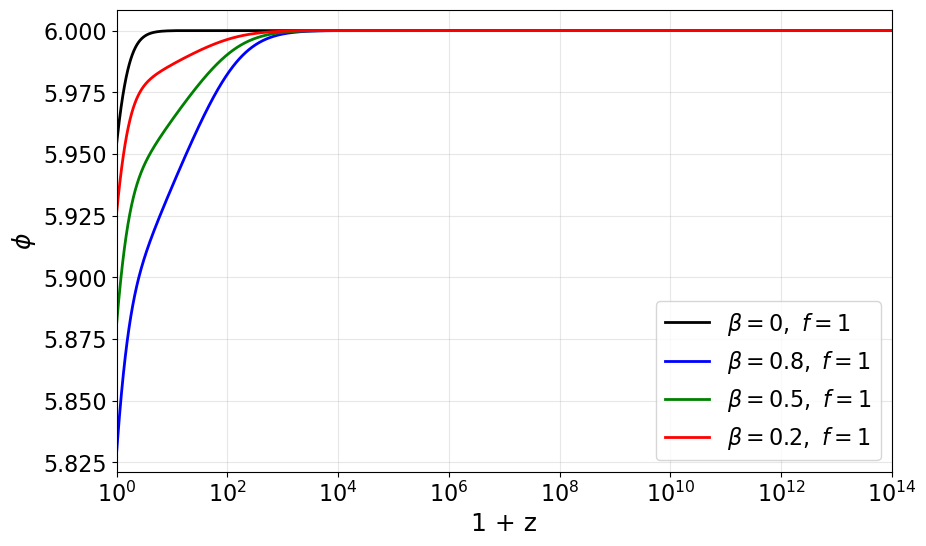

In [7]:
plt.figure(figsize=(10, 6))

plt.plot(1 + z1, phi_scf1, 'black', linewidth=2, label=r'$\beta=0, \ f=1$')
plt.plot(1 + z2, phi_scf2, 'b-', linewidth=2, label=r'$\beta=0.8, \ f=1$')
plt.plot(1 + z3, phi_scf3, 'g-', linewidth=2, label=r'$\beta=0.5, \ f=1$')
plt.plot(1 + z4, phi_scf4, 'r-', linewidth=2, label=r'$\beta=0.2, \ f=1$')

plt.xscale('log')

plt.xlabel('1 + z', fontsize=18)
plt.ylabel(r'$\phi$', fontsize=18)

# Increase tick label size
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.xlim(1e0,1e14)

plt.legend(fontsize=16)

plt.grid(True, alpha=0.3)

plt.savefig('phi_z_beta.pdf', bbox_inches='tight')
plt.show()


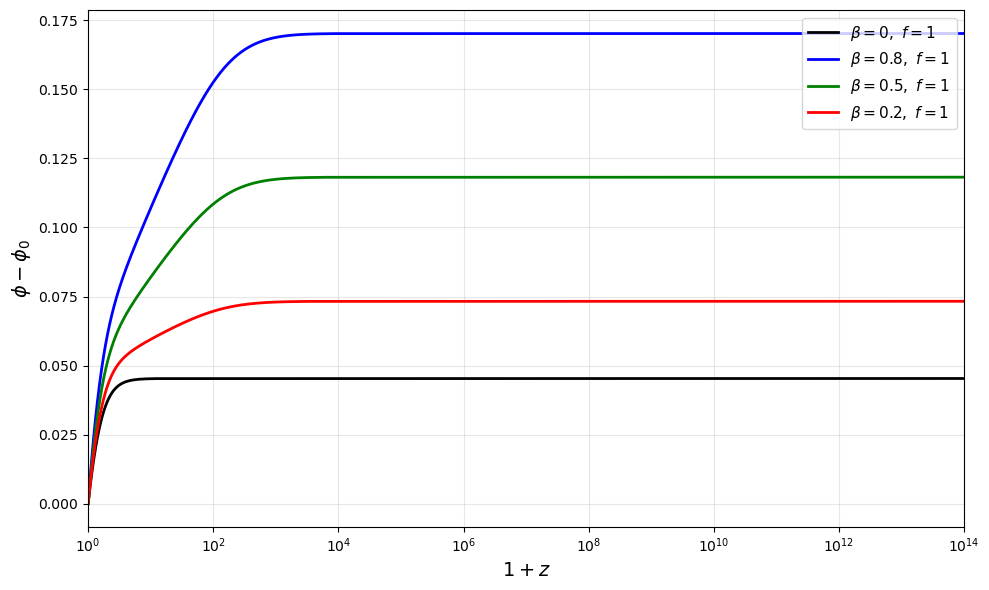

In [8]:
beta_ncdm1 = 0
beta_ncdm2 = 0.8
beta_ncdm3 = 0.5
beta_ncdm4 = 0.2


# Plot beta * phi to see coupling strength evolution
fig, ax = plt.subplots(figsize=(10, 6))

plt.semilogx(1 + z1, (phi_scf1 - phi0_1), 'black', linewidth=2, label=r'$\beta=0, \ f=1$')
plt.semilogx(1 + z2, (phi_scf2 - phi0_2), 'b-', linewidth=2, label=r'$\beta=0.8, \ f=1$')
plt.semilogx(1 + z3, (phi_scf3 - phi0_3), 'g-', linewidth=2, label=r'$\beta=0.5, \ f=1$')
plt.semilogx(1 + z4, (phi_scf4 - phi0_4), 'r-', linewidth=2, label=r'$\beta=0.2, \ f=1$')

ax.set_xlabel(r'$1 + z$', fontsize=14)
ax.set_ylabel(r'$\phi - \phi_0$', fontsize=14)
ax.legend(fontsize=11, loc='upper right')
ax.grid(True, alpha=0.3)
plt.xlim(1e0,1e14)

plt.tight_layout()
plt.savefig('coupling_strength.pdf')
plt.show()

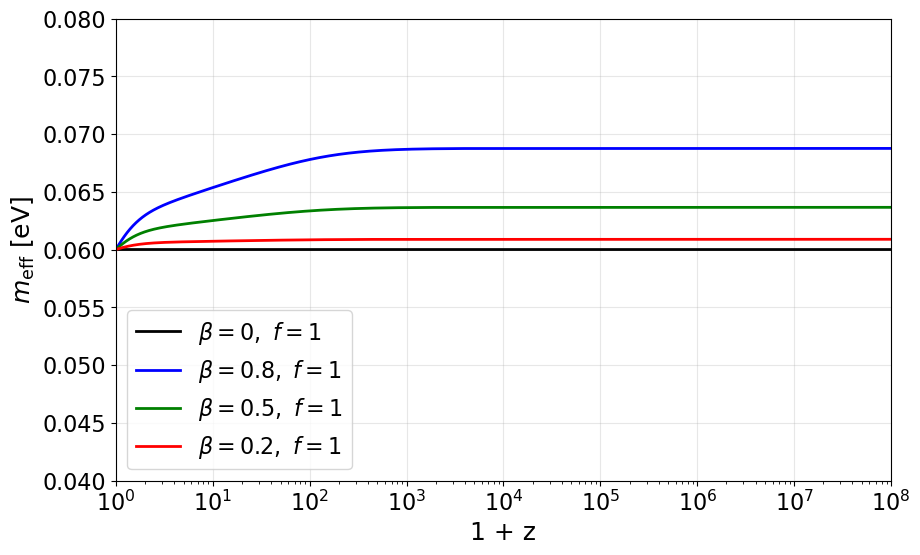

In [9]:
beta_ncdm1 = 0
beta_ncdm2 = 0.8
beta_ncdm3 = 0.5
beta_ncdm4 = 0.2

# Effective mass evolution
# m_eff(z) = m_ν,0 * exp(β * (φ(z) - φ_0))
m_eff1 = 0.06* np.exp(beta_ncdm1 * (phi_scf1 - phi0_1))
m_eff2 = 0.06 * np.exp(beta_ncdm2 * (phi_scf2 - phi0_2))
m_eff3 = 0.06 * np.exp(beta_ncdm3 * (phi_scf3 - phi0_3))
m_eff4 = 0.06 * np.exp(beta_ncdm4 * (phi_scf4 - phi0_4))

# Plot
plt.figure(figsize=(10, 6))

plt.semilogx(z1 + 1, m_eff1, 'black', linewidth=2, label=r'$\beta=0, \ f=1$')
plt.semilogx(z2 + 1 , m_eff2, 'b-', linewidth=2, label=r'$\beta=0.8, \ f=1$')
plt.semilogx(z3 + 1, m_eff3, 'g-', linewidth=2, label=r'$\beta=0.5, \ f=1$')
plt.semilogx(z4 + 1, m_eff4, 'r-', linewidth=2, label=r'$\beta=0.2, \ f=1$')

plt.xlabel('1 + z', fontsize=18)
plt.ylabel(r'$m_{\rm eff}$ [eV]', fontsize=18)

# Increase tick sizes
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

# Inverted x-axis limits as in your code
plt.xlim(1e0,1e8)
plt.ylim(0.04,0.08)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=16)

plt.savefig('m_eff_vs_z.pdf', bbox_inches='tight')
plt.show()


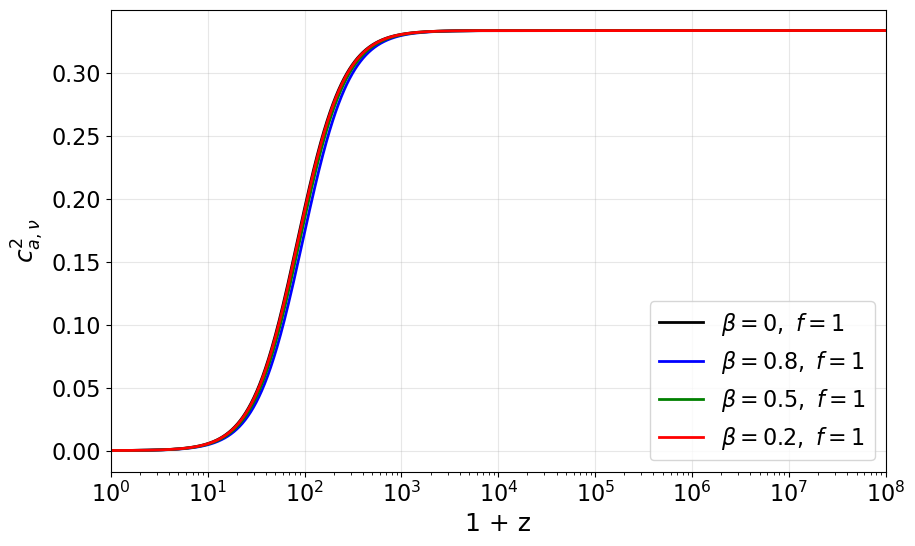

In [10]:
plt.figure(figsize=(10, 6))

plt.semilogx(1 + z1, ca2_nu1, 'black', linewidth=2, label=r'$\beta=0, \ f=1$')
plt.semilogx(1 + z2, ca2_nu2, 'b-', linewidth=2, label=r'$\beta=0.8, \ f=1$')
plt.semilogx(1 + z3, ca2_nu3, 'g-', linewidth=2, label=r'$\beta=0.5, \ f=1$')
plt.semilogx(1 + z4, ca2_nu4, 'r-', linewidth=2, label=r'$\beta=0.2, \ f=1$')

#plt.xscale('log')

plt.xlabel('1 + z', fontsize=18)
plt.ylabel(r"$c_{a,\nu}^2$", fontsize=18)

# Increase tick label size
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.xlim(1e0,1e8)

plt.legend(fontsize=16)

plt.grid(True, alpha=0.3)

plt.savefig('ca2.pdf', bbox_inches='tight')
plt.show()

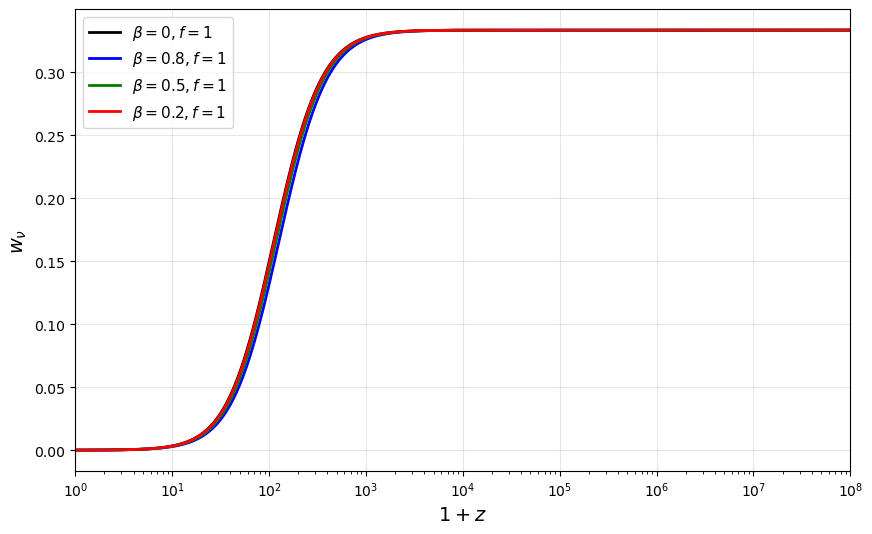

In [11]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# Single figure with all models

fig, ax = plt.subplots(figsize=(10, 6))

ax.semilogx(1 + z1, w_nu1, 'black', linewidth=2, label=r'$\beta=0, f=1$')
ax.semilogx(1 + z2, w_nu2, 'b-', linewidth=2, label=r'$\beta=0.8, f=1$')
ax.semilogx(1 + z3, w_nu3, 'g-', linewidth=2, label=r'$\beta=0.5, f=1$')
ax.semilogx(1 + z4, w_nu4, 'r-', linewidth=2, label=r'$\beta=0.2, f=1$')
plt.xlim(1e0,1e8)
ax.legend(fontsize=11, loc='upper left')
ax.grid(True, alpha=0.3)
ax.set_xlabel(r'$1+z$', fontsize=14)
ax.set_ylabel(r'$w_\nu$', fontsize=14)
plt.savefig('w_nu_all_models.pdf')
plt.show()

# Add inset
#axins = inset_axes(ax, width="35%", height="35%", loc='center right')
#axins.semilogx(1 + z1, w_nu1, 'black', linewidth=1.5)
#axins.semilogx(1 + z2, w_nu2, 'b-', linewidth=1.5)
#axins.semilogx(1 + z3, w_nu3, 'g-', linewidth=1.5)
#axins.semilogx(1 + z4, w_nu4, 'r-', linewidth=1.5)
#axins.set_xlim(1e4, 1e1)  # Zoom on transition
#axins.grid(True, alpha=0.3)

#plt.gca().invert_xaxis()



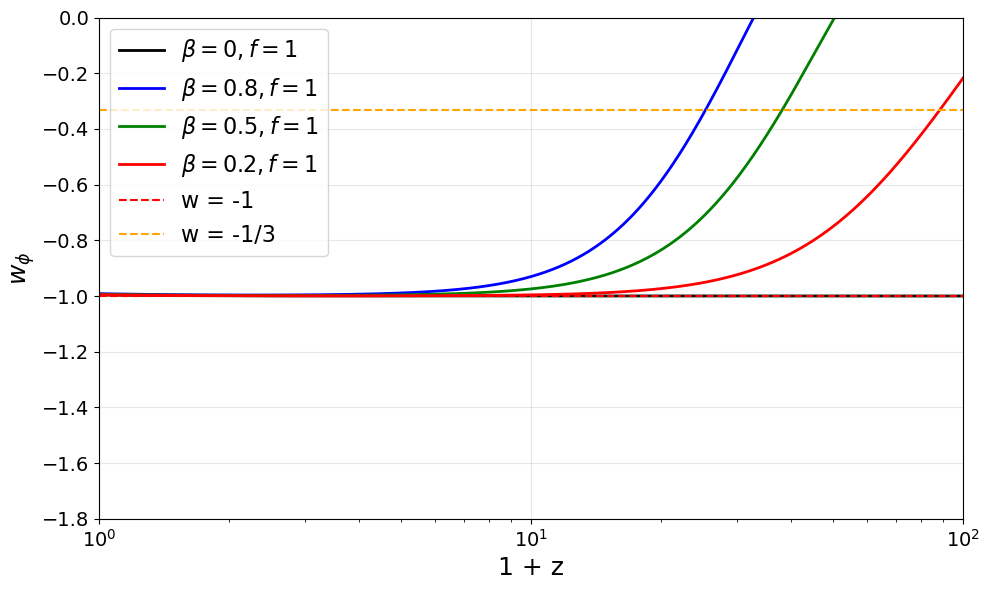

In [12]:
# Plot w_φ vs redshift
fig, ax = plt.subplots(figsize=(10, 6))

ax.semilogx(1 + z1, w_phi1, 'black', linewidth=2, label=r'$\beta=0, f=1$')
ax.semilogx(1 + z2, w_phi2, 'b-', linewidth=2, label=r'$\beta=0.8, f=1$')
ax.semilogx(1 + z3, w_phi3, 'g-', linewidth=2, label=r'$\beta=0.5, f=1$')
ax.semilogx(1 + z4, w_phi4, 'r-', linewidth=2, label=r'$\beta=0.2, f=1$')

ax.set_xlabel('1 + z', fontsize=18)
ax.set_ylabel(r'$w_\phi$', fontsize=18)

ax.set_xlim(1e0, 1e2)
ax.set_ylim(-1.8, 0.0)

# Increase tick label size
ax.tick_params(axis='both', which='major', labelsize=14)

ax.axhline(-1, color='red', linestyle='--', label='w = -1')
ax.axhline(-1/3, color='orange', linestyle='--', label='w = -1/3')

ax.legend(fontsize=16)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('w_phi_eos.pdf')
plt.show()


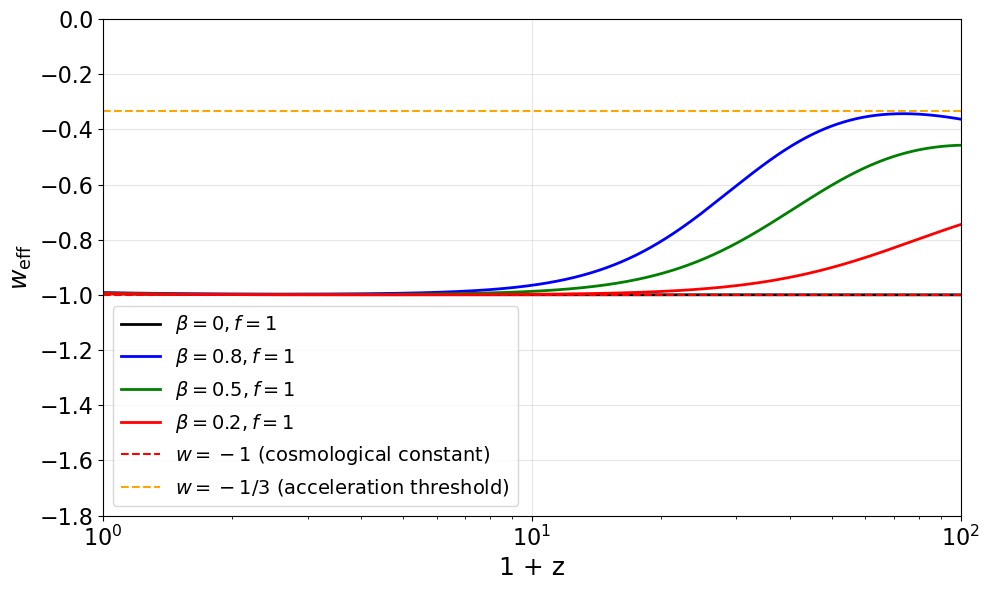

In [13]:
# Plot w_eff vs redshift
fig, ax = plt.subplots(figsize=(10, 6))

ax.semilogx(1 + z1, w_eff1, 'black', linewidth=2, label=r'$\beta=0, f=1$')
ax.semilogx(1 + z2, w_eff2, 'b-', linewidth=2, label=r'$\beta=0.8, f=1$')
ax.semilogx(1 + z3, w_eff3, 'g-', linewidth=2, label=r'$\beta=0.5, f=1$')
ax.semilogx(1 + z4, w_eff4, 'r-', linewidth=2, label=r'$\beta=0.2, f=1$')

ax.set_xlabel('1 + z', fontsize=18)
ax.set_ylabel(r'$w_{\rm eff}$', fontsize=18)

# Increase tick label size
ax.tick_params(axis='both', which='major', labelsize=16)


ax.set_xlim(1e0, 1e2)
ax.set_ylim(-1.8, 0.0)

ax.axhline(-1, color='red', linestyle='--', linewidth=1.5,
           label=r'$w = -1$ (cosmological constant)')
ax.axhline(-1/3, color='orange', linestyle='--', linewidth=1.5,
           label=r'$w = -1/3$ (acceleration threshold)')

ax.legend(fontsize=14)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('w_eff_eos.pdf', bbox_inches='tight')
plt.show()


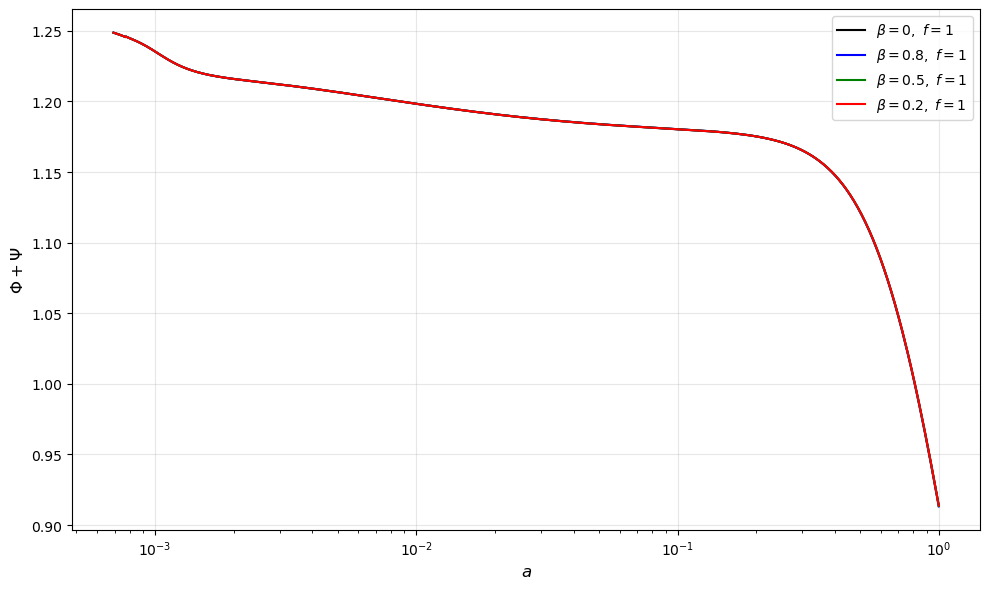

In [14]:
# Convert tau to scale factor
a_array1 = 1.0 / (1.0 + z_array1)
a_array2 = 1.0 / (1.0 + z_array2)
a_array3 = 1.0 / (1.0 + z_array3)
a_array4 = 1.0 / (1.0 + z_array4)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(a_array1, phi_plus_psi1, 'black', label=r'$\beta=0, \ f=1$')
plt.plot(a_array2, phi_plus_psi2, 'b-', label=r'$\beta=0.8, \ f=1$')
plt.plot(a_array3, phi_plus_psi3, 'g-', label=r'$\beta=0.5, \ f=1$')
plt.plot(a_array4, phi_plus_psi4, 'r-', label=r'$\beta=0.2, \ f=1$')

plt.xlabel('$a$', fontsize=12)
plt.ylabel(r'$\Phi + \Psi$', fontsize=12)  # Specify which k
plt.xscale('log')
plt.grid(True, alpha=0.3)
plt.legend(fontsize=10)
plt.tight_layout()  # Prevents label cutoff
plt.savefig('phi_plus_psi_beta.pdf', dpi=300, bbox_inches='tight')  # Higher quality
plt.show()



In [15]:
# get lesned C_l spectra
cls1 = model1.lensed_cl(2500)
cls2 = model2.lensed_cl(2500)
cls3 = model3.lensed_cl(2500)
cls4 = model4.lensed_cl(2500)

# Model 1: β=0

model1.set({'temperature contributions': 'lisw'})
model1.compute()
cl_eisw1 = model1.raw_cl(2500)

# Model 2: β=1

model2.set({'temperature contributions': 'lisw'})
model2.compute()
cl_eisw2 = model2.raw_cl(2500)

# Model 3: β=-0.7

model3.set({'temperature contributions': 'lisw'})
model3.compute()
cl_eisw3 = model3.raw_cl(2500)

In [16]:
# get multipoles l
ll1 = cls1['ell'][2:]
# get CMB temperature spectrum C_l^TT
clTT1 = cls1['tt'][2:]
# get CMB polarisation spectrum C_l^EE
clEE1 = cls1['ee'][2:]


ll2 = cls2['ell'][2:]
# get CMB temperature spectrum C_l^TT
clTT2 = cls2['tt'][2:]
# get CMB polarisation spectrum C_l^EE
clEE2 = cls2['ee'][2:]

ll3 = cls3['ell'][2:]
# get CMB temperature spectrum C_l^TT
clTT3 = cls3['tt'][2:]
# get CMB polarisation spectrum C_l^EE
clEE3 = cls3['ee'][2:]

ll4 = cls4['ell'][2:]
# get CMB temperature spectrum C_l^TT
clTT4 = cls4['tt'][2:]
# get CMB polarisation spectrum C_l^EE
clEE4 = cls4['ee'][2:]



In [ ]:
# plot C_l^TT
T_CMB = 2.7255e6
plt.figure(figsize=(10, 6))

plt.xscale('log')
plt.yscale('linear')
plt.xlim(2, 1500)

plt.xlabel(r'$\ell$', fontsize=18)
plt.ylabel(r'$[\ell(\ell+1)/2\pi]\, C_\ell^{\mathrm{TT}}$', fontsize=18)

# Increase tick size
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

# Plot lines with consistent linewidth
plt.plot(ll1, (clTT1*ll1*(ll1+1))/(2.*np.pi)*T_CMB**2,
         color='black', linestyle='-', linewidth=2, label=r'$\beta=0, \ f=1$')

plt.plot(ll2, (clTT2*ll2*(ll2+1))/(2.*np.pi)*T_CMB**2,
         color='b', linestyle='--', linewidth=2, label=r'$\beta=0.8, \ f=1$')

plt.plot(ll3, (clTT3*ll3*(ll3+1))/(2.*np.pi)*T_CMB**2,
         color='g', linestyle=':', linewidth=2, label=r'$\beta=0.5, \ f=1$')

plt.plot(ll4, (clTT4*ll4*(ll4+1))/(2.*np.pi)*T_CMB**2,
         color='r', linestyle='-.', linewidth=2, label=r'$\beta=0.2, \ f=1$')

plt.legend(fontsize=16)
plt.grid(True, alpha=0.3)

plt.savefig('mnu3_cltt_beta.pdf', bbox_inches='tight')
plt.show()


In [ ]:
# get P(k) at redhsift z=0
import numpy as np
kk = np.geomspace(1e-4,3.0,num=1000) # k in h/Mpc
h1 = model1.h() # get reduced Hubble for conversions to h/Mpc
h2 = model2.h() # get reduced Hubble for conversions to h/Mpc
h3 = model3.h() # get reduced Hubble for conversions to h/Mpc

h4 = model4.h() # get reduced Hubble for conversions to h/Mpc

# Note that kk*h is the array of k in 1/Mpc
Pk1 = model1.get_pk_all(kk*h1,0.)*h1**3 # get power spectrum, converted into (Mpc/h)^3 units, instead of the default Mpc^3 units
Pk2 = model2.get_pk_all(kk*h2,0.)*h2**3 # get power spectrum, converted into (Mpc/h)^3 units, instead of the default Mpc^3 units
Pk3 = model3.get_pk_all(kk*h3,0.)*h3**3 # get power spectrum, converted into (Mpc/h)^3 units, instead of the default Mpc^3 units
Pk4 = model4.get_pk_all(kk*h4,0.)*h4**3 # get power spectrum, converted into (Mpc/h)^3 units, instead of the default Mpc^3 units


# By default, this is the non-linear matter power spectrum; to get the linear one,
# pass the optional argument 'nonlinear=False' to .get_pk_all()

In [ ]:
# plot P(k)
plt.figure(figsize=(10, 6))

plt.xscale('log')
plt.yscale('log')
plt.xlim(1e-4, 1e1)
plt.ylim(1e1, 1e5)

plt.xlabel(r'$k \,\, [h/\mathrm{Mpc}]$', fontsize=18)
plt.ylabel(r'$P(k) \,\, [\mathrm{Mpc}/h]^3$', fontsize=18)

# Increase tick label sizes
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

# Plot with consistent line width
plt.plot(kk, Pk1, 'black', linewidth=2, label=r'$\beta=0, \ f=1$')
plt.plot(kk, Pk2, 'b-', linewidth=2, label=r'$\beta=0.8, \ f=1$')
plt.plot(kk, Pk3, 'g-', linewidth=2, label=r'$\beta=0.5, \ f=1$')
plt.plot(kk, Pk4, 'r-', linewidth=2, label=r'$\beta=0.2, \ f=1$')

plt.legend(fontsize=16)
plt.grid(True, alpha=0.3)

plt.savefig('mnu3_pk_beta.pdf', bbox_inches='tight')
plt.show()


In [ ]:
# Alternative: Plot absolute densities instead of Omega
fig1, ax1 = plt.subplots(figsize=(10, 7))

ax1.loglog(1 + z1, rho_g1, label='Photons', linewidth=2)
ax1.loglog(1 + z1, rho_ur1, label='Neutrinos (massless)', linewidth=2)
ax1.loglog(1 + z1, rho_nu1, label='Neutrinos (massive)', linewidth=2)
ax1.loglog(1 + z1, rho_b1, label='Baryons', linewidth=2)
ax1.loglog(1 + z1, rho_cdm1, label='CDM', linewidth=2)
ax1.loglog(1 + z1, rho_scf1, label='Scalar Field', linewidth=2)


ax1.set_xlabel(r'$a$', fontsize=14)
ax1.set_ylabel(r'$\rho$', fontsize=14)
ax1.set_title(r'$\beta = 0$ and $f = 1$', fontsize=16)
ax1.legend(fontsize=11, loc='best')
ax1.grid(True, alpha=0.3, which='both')
ax1.set_xlim(a1.min(), a1.max())
plt.savefig('rho_1.pdf', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

# Alternative: Plot absolute densities instead of Omega
fig2, ax2 = plt.subplots(figsize=(10, 7))

# Use regular plot instead of loglog
ax2.loglog(1 + z2, rho_g2, label='Photons', linewidth=2)
ax2.loglog(1 + z2, rho_ur2, label='Neutrinos (massless)', linewidth=2)
ax2.loglog(1 + z2, rho_nu2, label='Neutrinos (massive)', linewidth=2)
ax2.loglog(1 + z2, rho_b2, label='Baryons', linewidth=2)
ax2.loglog(1 + z2, rho_cdm2, label='CDM', linewidth=2)
ax2.loglog(1 + z2, rho_scf2, label='Scalar Field', linewidth=2)


ax2.set_xlabel(r'$a$', fontsize=14)
ax2.set_ylabel(r'$\rho$', fontsize=14)
ax2.set_title(r'$\beta = 1$ and $f = 1$', fontsize=16)
ax2.legend(fontsize=11, loc='best')
ax2.grid(True, alpha=0.3, which='both')
ax2.set_xlim(a2.min(), a2.max())
plt.savefig('rho_2.pdf', dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()

# Alternative: Plot absolute densities instead of Omega
fig3, ax3 = plt.subplots(figsize=(10, 7))

# Use regular plot instead of loglog
ax3.loglog(1 + z3, rho_g3, label='Photons', linewidth=2)
ax3.loglog(a3, rho_ur3, label='Neutrinos (massless)', linewidth=2)
ax3.loglog(a3, rho_nu3, label='Neutrinos (massive)', linewidth=2)
ax3.loglog(a3, rho_b3, label='Baryons', linewidth=2)
ax3.loglog(a3, rho_cdm3, label='CDM', linewidth=2)
ax3.loglog(a3, rho_scf3, label='Scalar Field', linewidth=2)


ax3.set_xlabel(r'$a$', fontsize=14)
ax3.set_ylabel(r'$\rho$', fontsize=14)
ax3.set_title(r'$\beta = 0.5$ and $f = 1$', fontsize=16)
ax3.legend(fontsize=11, loc='best')
ax3.grid(True, alpha=0.3, which='both')
ax3.set_xlim(a3.min(), a3.max())
plt.savefig('rho_3.pdf', dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()


# Alternative: Plot absolute densities instead of Omega
fig4, ax4 = plt.subplots(figsize=(10, 7))

# Use regular plot instead of loglog
ax4.loglog(a4, rho_g4, label='Photons', linewidth=2)
ax4.loglog(a4, rho_ur4, label='Neutrinos (massless)', linewidth=2)
ax4.loglog(a4, rho_nu4, label='Neutrinos (massive)', linewidth=2)
ax4.loglog(a4, rho_b4, label='Baryons', linewidth=2)
ax4.loglog(a4, rho_cdm4, label='CDM', linewidth=2)
ax4.loglog(a4, rho_scf4, label='Scalar Field', linewidth=2)


ax4.set_xlabel(r'$a$', fontsize=14)
ax4.set_ylabel(r'$\rho$', fontsize=14)
ax4.set_title(r'$\beta = 0.2$ and $f = 1$', fontsize=16)
ax4.legend(fontsize=11, loc='best')
ax4.grid(True, alpha=0.3, which='both')
ax4.set_xlim(a4.min(), a4.max())
plt.savefig('rho_4.pdf', dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()

In [ ]:
# Compute m_eff^2 (general formula, valid for all regimes)
# m_eff^2 = d²V/dφ² + β² (ρ_ν - 3p_ν)
m_eff_squared = ddV_scf + beta_val**2 * (rho_nu - 3*p_nu)

# Compute the ratio
m_over_H = m_eff_squared / H**2

# For stability, we need m_eff/H ≲ 1
print(f"Range of m_eff/H: [{np.min(m_over_H):.4f}, {np.max(m_over_H):.4f}]")
print(f"m_eff/H at z=0: {m_over_H[0]:.4f}")

# Check if the stability condition is satisfied
unstable_indices = np.where(m_over_H > 1.0)[0]
if len(unstable_indices) > 0:
    print(f"WARNING: {len(unstable_indices)} redshift points have m_eff/H > 1 (potentially unstable)")
    print(f"First unstable redshift: z = {z2[unstable_indices[0]]:.4f}")
else:
    print("Model appears stable: m_eff/H ≲ 1 throughout evolution")

# Plot
plt.figure(figsize=(10, 6))
plt.plot(a, m_over_H, 'b-', label=r'$pNGB$')

plt.xlabel('a', fontsize=18)
plt.ylabel(r'$m_{\rm eff,\phi}/H$', fontsize=18)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.yscale('log')
plt.xscale('log')
plt.xlim(1e-6, 1e0) 
plt.ylim(1e-5, 1e1)

plt.axhline(y=1.0, color='r', linestyle='--', alpha=0.5, label='Stability threshold')
plt.grid(True, alpha=0.3)
plt.legend(fontsize=16)

plt.savefig('mphi_H.pdf', bbox_inches='tight')
plt.show()

In [ ]:


# Plot V_eff
plt.figure(figsize=(10, 6))
plt.plot(z1+1, V_eff1, 'black', label=r'$\beta=0,  f=2$')
plt.plot(z2+1, V_eff2, 'b-', label=r'$\beta=1, \ f=2$')
plt.plot(z3+1, V_eff3, 'g-', label=r'$\beta=-0.5, \ f=2$')
plt.plot(z4+1, V_eff4, 'r-', label=r'$\beta=1, \ f=3$')

plt.xlabel('z+1', fontsize=12)
plt.ylabel(r'$V_{\rm eff}$', fontsize=12)
plt.xscale('log')
plt.xlim(1e0,1e8)
plt.yscale('log')
plt.grid(True, alpha=0.3)
plt.legend(fontsize=10)
plt.tight_layout()
plt.savefig('V_eff.pdf', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
# Save the data
np.savez('meff_data_model2.npz', 
         a=a2, 
         z=z2,
         m_eff_over_H=m_eff_over_H2,
         m_eff=m_eff2,
         H=H2,
         rho_nu=rho_nu2,
         p_nu=p_nu2,
         phi_scf=phi_scf2,
         beta=beta2_val)

print("Data saved to meff_data_model2.npz")

